# Topical Lectures, Controls
## Extra: flying a helix

This notebook takes you from switching the drone on to flying a helix, all in one place: find the drone, connect, check it, test the abort, plan the helix, fly it and look at what it recorded. The drone flies under its own firmware controllers, as in part 2.

### How a helix is flown

A helix is a circle that climbs. The drone gets three setpoints **at the same time**:

* a forward speed `v` in its own frame,
* a yaw rate `ω`: it keeps turning to the left,
* a climb rate `v_z`.

Because the drone keeps turning while it flies forward, its "forward" sweeps around, and its track over the floor is a circle of radius

$$r = \frac{v}{\omega} .$$

One turn is a distance of $2\pi r$ and takes $T = 2\pi r / v$. Adding a constant `v_z` lifts each turn by $v_z T$: a helix. With `('helix', radius, height, turns)`, `fly_path` works out `ω` and `v_z` for you and sends all three in one setpoint, `start_linear_motion(v, 0, v_z, ω)`.

The firmware does the rest: the Kalman filter estimates the position from the flow deck, and its velocity loop turns the velocity setpoints into tilt and motor commands.

### Safety

* Fly only in the marked area. The helix needs a free circle of `2 × radius` plus about 0.5 m around the start.
* One person at the keyboard, one watching the drone, nobody within arm's length while the motors run.
* The person at the keyboard keeps the abort window in front, clicked once so that it takes the keys. **Enter** aborts and lands.
* `fly_path` lands by itself when the drone leaves a 1.5 m box around the start, when no state arrives any more, when the battery drops below 3.1 V or when the flow deck stops delivering. It refuses a path that goes above 1.5 m or below 0.2 m before it takes off.
* Full battery: above 3.5 V at rest. A climbing helix costs more than a hover.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import crazyflie

%matplotlib inline

# The label of your drone as it reads on the sticker:
# LABEL = 2, or LABEL = 'A' for a letter.
LABEL = 4
URI = crazyflie.drone_uri(LABEL)
print(URI)

radio://0/30/2M/E7E7E7E704


## Step 1: find the drone

Switch the drone on (blue LEDs), plug in the Crazyradio dongle and close cfclient. The cell looks for your drone on all channels. A warning means the drone is not on the channel of its label: ask an instructor before you go on.

In [5]:
crazyflie.find_drones(LABEL)

drones in range (label, URI, what to enter in the next cell):
  label 4    radio://0/30/2M/E7E7E7E704   LABEL = 4


{4: 'radio://0/30/2M/E7E7E7E704'}

## Step 2: connect and check

Put the drone **on the floor of the flying area**. The cell prints the battery, whether the flow deck is detected, the supervisor flags and whether the position estimate stays still on the ground, then blinks the LEDs. Make sure **your** drone blinks.

* `flow deck: NOT attached`: reseat the deck.
* `is locked: yes`: run the cell after this one.
* `WARNING: the position estimate runs away` or `does not follow the height sensor`: switch the drone off and on and run this cell again.

In [6]:
with crazyflie.connect(URI) as scf:
    crazyflie.status(scf)
    crazyflie.identify(scf)

Drone status of radio://0/30/2M/E7E7E7E704
  battery      : in use, 3.96 V at rest, 61 % of a full charge
  flight       : ok
  flow deck    : attached
  can be armed : no
  is armed     : yes
  is tumbled   : no
  is locked    : no
  height       : estimate 0.016 m, sensor 0.021 m, agree
  position     : estimate moved 0.006 m in 2 s on the ground, ok
the four LEDs of your drone blink 3 times


In [7]:
# Only when the status says locked: clear the lock, then check again.
with crazyflie.connect(URI) as scf:
    crazyflie.recover(scf)
    crazyflie.status(scf)

Drone status of radio://0/30/2M/E7E7E7E704
  battery      : in use, 3.96 V at rest, 61 % of a full charge
  flight       : ok
  flow deck    : attached
  can be armed : no
  is armed     : yes
  is tumbled   : no
  is locked    : no
  height       : estimate 0.014 m, sensor 0.022 m, agree
  position     : estimate moved 0.005 m in 2 s on the ground, ok


## Step 3: test the abort

Once per session. A dummy loop of 10 s opens the same abort window as the flight. Click into the window and press Enter: the loop must report the abort. If it does not, do not fly from this program.

In [ ]:
crazyflie.bench_test_abort()

## Step 4: plan the helix

Choose the helix here. The cell prints what the drone will be told, draws the planned path and checks it against the limits. Nothing flies yet.

* `RADIUS`: the radius of the circle in metres. Positive turns left, negative turns right. Start with 0.3 m.
* `CLIMB`: the height gained over the whole helix in metres. Negative descends.
* `TURNS`: the number of full turns.
* `SPEED`: the speed along the circle in m/s. The climb is limited to 0.2 m/s; if it needs longer, the speed along the circle drops.
* `Z0`: the take-off height.

A small radius at a high speed means a high yaw rate and a tight turn, which the velocity loop follows with a lag: the measured circle comes out smaller and shifted. Start gently.

speed along the circle 0.25 m/s, yaw rate +47.7 deg/s, climb 3.5 cm/s
one turn takes 7.5 s, the helix 11.3 s, height 0.50 m -> 0.90 m
the circle spans x -0.30 to +0.30 m, y +0.00 to +0.60 m from the start


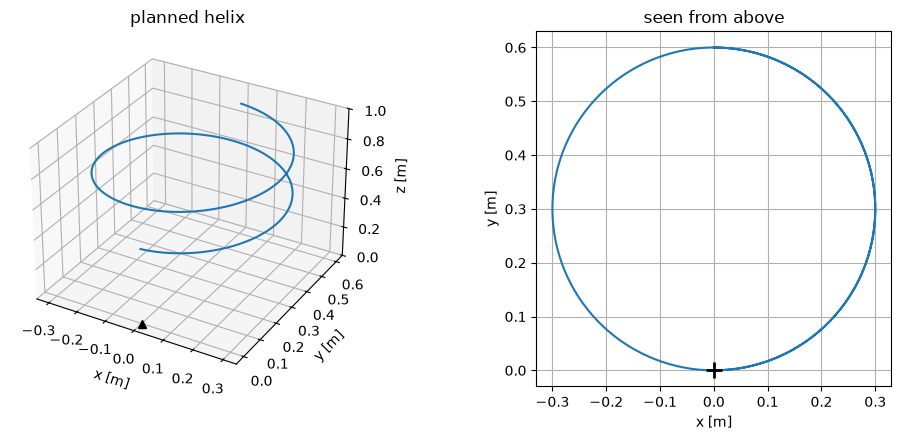

In [8]:
RADIUS = 0.3     # m, positive: to the left
CLIMB = 0.4      # m over the whole helix
TURNS = 1.5
SPEED = 0.25     # m/s along the circle
Z0 = 0.5         # m, take-off height

arc = 2 * np.pi * abs(RADIUS) * TURNS
duration = max(arc / SPEED, abs(CLIMB) / 0.2)
v = arc / duration
v_z = CLIMB / duration
yaw_rate = np.degrees(v / RADIUS)
print(f'speed along the circle {v:.2f} m/s, yaw rate {yaw_rate:+.1f} deg/s, climb {100 * v_z:.1f} cm/s')
print(f'one turn takes {360 / abs(yaw_rate):.1f} s, the helix {duration:.1f} s, height {Z0:.2f} m -> {Z0 + CLIMB:.2f} m')

# the planned path in the frame of the room: +x is where the drone points at take-off
t = np.linspace(0, duration, 400)
heading = np.radians(yaw_rate) * t
plan_x = RADIUS * np.sin(heading)
plan_y = RADIUS * (1 - np.cos(heading))
plan_z = Z0 + v_z * t
print(f'the circle spans x {plan_x.min():+.2f} to {plan_x.max():+.2f} m, y {plan_y.min():+.2f} to {plan_y.max():+.2f} m from the start')
if max(abs(plan_x).max(), abs(plan_y).max()) > 1.2:
    print('WARNING: the circle comes close to the 1.5 m fence; make the radius smaller')
if not 0.2 <= Z0 + CLIMB <= 1.5:
    print('WARNING: the end height is outside 0.2 to 1.5 m; fly_path will refuse this path')

fig = plt.figure(figsize=(10, 4.5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot(plan_x, plan_y, plan_z)
ax.plot([0], [0], [0], 'k^')
ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_zlabel('z [m]')
ax.set_zlim(0, max(plan_z) + 0.1)
ax.set_title('planned helix')
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(plan_x, plan_y)
ax2.plot(0, 0, 'k+', ms=12, mew=2)
ax2.set_xlabel('x [m]'); ax2.set_ylabel('y [m]')
ax2.set_aspect('equal'); ax2.grid()
ax2.set_title('seen from above')
plt.tight_layout()

## Step 5: fly

Put the drone flat on the floor in the middle of the free space, with its forward side (between the motors M1 and M4, the blue LEDs at the back) pointing along the room's `+x`. With a positive radius the circle lies to the **left** of the drone. Announce the flight and run the cell.

What happens, as the printout shows it:

1. connect, reset the estimator, check for 1.5 s that the estimate stays still on the ground,
2. arm, take off to `Z0`, hover for 2 s,
3. hold for 1 s, then the helix: forward speed, yaw rate and climb rate together,
4. hold for 2 s at the top, then land: a quick descent to 10 cm, then a slow touch-down.

Enter in the abort window lands the drone at any point. The cell ends with `landed`, and the flight is saved under the label `helix`.

In [ ]:
PATH = [('helix', RADIUS, CLIMB, TURNS)]
RUN_LABEL = 'helix'

run = crazyflie.fly_path(PATH, uri=URI, z=Z0, speed=SPEED)
name = crazyflie.save(run, RUN_LABEL)

no abort window (ValueError: Unknown format code 'd' for object of type 'str'); the input box of the notebook takes Enter instead
[ 2.3 s] connected, estimator reset, 1.5 s watching the estimate on the ground
[ 3.9 s] deck ok, armed, take-off to 0.50 m
[ 8.5 s] in the air, 2.0 s to settle at hover
[10.5 s] path starts at x 0.09 m, y 0.01 m: helix 0.3 0.4 1.5
[25.3 s] landing
path completed
loop iterations: 717  logged rows: {'state': 1388, 'sensor': 1388, 'power': 555, 'land': 1388}
landed. Press Enter once to close the input box; the flight is over, Enter does nothing else now
saved data/flight_4_1631_helix_state.csv
saved data/flight_4_1631_helix_sensor.csv
saved data/flight_4_1631_helix_power.csv
saved data/flight_4_1631_helix_land.csv
saved data/flight_4_1631_helix_pid.csv
saved data/flight_4_1631_helix_info.csv
4_1631_helix
  x: rise to 90% 0.02 s, overshoot 0.255 m, last 2 s max |error| 0.101 m (mean +0.066 m), clamp 5% of step
  y: rise to 90% 3.18 s, overshoot 0.053 m, last 2 s

[63.1 s] ABORT requested, landing as soon as possible


: 

## Step 6: what the drone recorded

Left: the measured path in 3D, with the planned helix, from the logged state estimate. Middle: seen from above: does the circle close, is it round, is it the planned size? Right: the height against time, the estimate of the firmware and the reading of the range sensor.

Things to look for:

* **The size of the circle.** The velocity loop follows with a lag (the `tau` of part 4), so in a tight turn the drone cuts inside the planned circle.
* **Drift.** The flow deck measures motion, not position: small errors add up, and after a few turns the circle wanders. The printout gives the distance between the start and the end of the circle, seen from above.
* **The climb.** The height should rise as a straight line. The range sensor and the estimate should agree.

In [ ]:
def show_helix(name):
    r = crazyflie.load_run(name)
    pid, state, sensor = r['pid'], r['state'], r['sensor']
    x0, y0 = pid['target_x'][0], pid['target_y'][0]
    # the logged state from the start of the path to the landing
    t_path = pid['t_ms'][pid['step'] > 0.5]
    in_path = (state['t_ms'] >= t_path[0]) & (state['t_ms'] <= t_path[-1])
    sx = state['stateEstimate.x'][in_path] - x0
    sy = state['stateEstimate.y'][in_path] - y0
    sz = state['stateEstimate.z'][in_path]
    fig = plt.figure(figsize=(15, 4.5))
    ax = fig.add_subplot(1, 3, 1, projection='3d')
    ax.plot(sx, sy, sz, label='measured')
    ax.plot(plan_x, plan_y, plan_z, 'k--', lw=0.8, label='planned')
    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_zlabel('z [m]')
    ax.set_zlim(0, max(sz.max(), plan_z.max()) + 0.1)
    ax.legend(fontsize=8)
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.plot(sx, sy, label='measured')
    ax2.plot(pid['target_x'] - x0, pid['target_y'] - y0, 'k--', lw=0.8, label='planned')
    ax2.plot(0, 0, 'k+', ms=12, mew=2)
    ax2.set_xlabel('x [m]'); ax2.set_ylabel('y [m]')
    ax2.set_aspect('equal'); ax2.grid(); ax2.legend(fontsize=8)
    ax3 = fig.add_subplot(1, 3, 3)
    t0 = state['t_ms'][0]
    ax3.plot((state['t_ms'] - t0) / 1000, state['stateEstimate.z'], label='estimate z')
    ax3.plot((sensor['t_ms'] - t0) / 1000, sensor['range.zrange'] / 1000, alpha=0.6, label='range sensor')
    ax3.axvspan((t_path[0] - t0) / 1000, (t_path[-1] - t0) / 1000, color='0.9', label='path')
    ax3.set_xlabel('t [s]'); ax3.set_ylabel('height [m]')
    ax3.grid(); ax3.legend(fontsize=8)
    plt.tight_layout()
    radius = np.median(np.hypot(sx, sy - RADIUS))       # the planned centre is RADIUS to the left of the start
    print(f"aborted: {r['info'].get('aborted') or 'no'}")
    print(f"measured radius about {radius:.2f} m (planned {abs(RADIUS):.2f} m), "
          f"height {sz[0]:.2f} m -> {sz[-1]:.2f} m (planned {Z0:.2f} -> {Z0 + CLIMB:.2f} m)")
    print(f"end of the path {100 * np.hypot(pid['x'][-1] - pid['target_x'][-1], pid['y'][-1] - pid['target_y'][-1]):.1f} cm "
          f"from the planned position")

show_helix(name)

## Play

Change one thing at a time, fly, look, and save each flight under its own `RUN_LABEL`.

* **Tighter.** `RADIUS = 0.2` at the same speed: the yaw rate goes up. How much smaller is the measured circle?
* **Faster.** `SPEED = 0.4` at `RADIUS = 0.3`. Watch where the circle bends inward.
* **The other way.** `RADIUS = -0.3` turns right.
* **Down again.** Climb and descend in one path, keeping the height between 0.2 and 1.5 m:
  `PATH = [('helix', 0.3, 0.4, 1.5), ('hold', 1.0), ('helix', -0.3, -0.4, 1.5)]`.
  The second helix turns right and descends, but the drone's heading has moved on by 1.5 turns, so the two circles do not lie on top of each other.
* **A flat circle.** `CLIMB = 0.0`, `TURNS = 2`: the drift of the flow deck from one turn to the next.

The planned path in step 4 is drawn for a single helix from the start. For a longer `PATH`, look at the planned line of `show_helix` (from above), which `fly_path` records for every move.

## If something goes wrong

* `No drone answers at ...`: the drone is off, or not on the channel of its label.
* `is locked: yes` after a tumble or a hard landing: run the recover cell; if it stays locked, switch the drone off and on.
* `the path reaches ... m height`: the helix would climb above 1.5 m or drop below 0.2 m; change `Z0` or `CLIMB`.
* `fence at ...`: the drone left the 1.5 m box; make the circle smaller or start more central.
* The circle drifts off although everything else looks fine: the floor has too little texture for the flow sensor. Fly over the mat.
* `state samples stale`: the radio link dropped. Keep the laptop close to the flying area.
* `height sensor frozen`, `does not follow the height sensor`: the deck stopped delivering. Switch the drone off and on and connect again.